# Homework 6 - Extra Practice

Austin Oliver | GitHub: awoliver335 | USC ID: 1949137702

Optional exercises: ISLR 5.4.2, 6.8.4, 8.4.4, and 9.7.2.

In [1]:
# Uncomment to install the project dependencies in this kernel.
# %pip install -r requirements.txt
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

SEED = 552
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False,
                     'axes.spines.right': False})


## ISLR 5.4.2: bootstrap inclusion

**(a)-(b)** Independent draws with replacement each avoid observation $j$ with probability $1-1/n$.

**(c)** Thus $P(j\text{ absent})=(1-1/n)^n$ and $P(j\text{ included})=1-(1-1/n)^n$.

**(d)-(f)** Inclusion probabilities at $n=5,100,10{,}000$ are $0.67232$, $0.63396766$, and $0.63213895$.

**(g)** The curve decreases from 1 toward $1-e^{-1}\approx0.63212$: about 63.2% of original observations appear in a large bootstrap sample.

**(h)** I simulate 10,000 samples of size 100 and check whether observation 4 appears. The theoretical probability is 0.63397, with Monte Carlo standard error $\sqrt{0.634(1-0.634)/10000}\approx0.00482$.

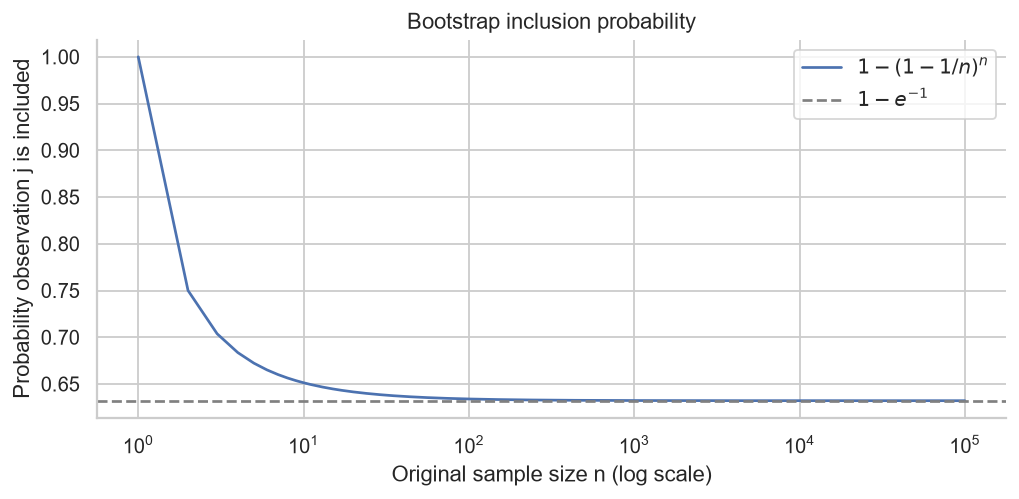

The simulated inclusion probability is 0.6238, compared with the theoretical value 0.633968. The difference is 2.11 Monte Carlo standard errors. This finite-simulation estimate varies with the random seed; more repetitions reduce Monte Carlo uncertainty.

In [2]:
sizes = np.arange(1, 100001)
inclusion = np.empty(len(sizes), dtype=float)
inclusion[0] = 1
inclusion[1:] = -np.expm1(sizes[1:] * np.log1p(-1 / sizes[1:]))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sizes, inclusion, label=r'$1-(1-1/n)^n$')
ax.axhline(1 - np.exp(-1), color='gray', linestyle='--', label=r'$1-e^{-1}$')
ax.set(xscale='log', xlabel='Original sample size n (log scale)',
        ylabel='Probability observation j is included', title='Bootstrap inclusion probability')
ax.legend()
plt.tight_layout()
plt.show()
rng = np.random.default_rng(SEED)
bootstrap_samples = rng.integers(1, 101, size=(10000, 100))
empirical_inclusion = (bootstrap_samples == 4).any(axis=1).mean()
theoretical_inclusion = 1 - .99**100
mc_se = np.sqrt(theoretical_inclusion * (1-theoretical_inclusion) / 10000)
display(Markdown(
    f'The simulated inclusion probability is {empirical_inclusion:.4f}, '
    f'compared with the theoretical value {theoretical_inclusion:.6f}. '
    f'The difference is {abs(empirical_inclusion-theoretical_inclusion)/mc_se:.2f} '
    'Monte Carlo standard errors. This finite-simulation estimate varies with the '
    'random seed; more repetitions reduce Monte Carlo uncertainty.'))


## ISLR 6.8.4: ridge regularization

The supplied ISLR places Chapter 6 exercises in **6.6**, not 6.8; I interpret this as **Chapter 6, Exercise 4**, minimizing $RSS+\lambda\sum_j\beta_j^2$ with an unpenalized intercept.

| Part | Choice as $\lambda$ increases | Reason |
|---|---|---|
| (a) Training RSS | **iii: increases** | Shrinkage moves away from least squares; RSS is nondecreasing. |
| (b) Test RSS | **ii: decreases, then increases** | Early variance reduction helps; excessive bias eventually hurts. |
| (c) Variance | **iv: decreases** | Shrinkage reduces sample sensitivity. |
| (d) Squared bias | **iii: increases** | Slopes are restricted toward zero. |
| (e) Irreducible error | **v: constant** | Response noise is unchanged. |

As $\lambda\to\infty$, the fit approaches the intercept-only mean. Bias and test-error trends are qualitative, not universal monotonicity claims.

## ISLR 8.4.4: tree and partition

**(a)** Split first at $X_1=1$: the right region predicts 5. On the left, split at $X_2=1$: the upper region predicts 15. Below, split at $X_1=0$: the left region predicts 3. Split the remaining region at $X_2=0$, predicting 10 below and 0 above. The tree labels both branches.

**(b)** The right panel's tree gives
$$\hat f(x)=\begin{cases}
-1.80,&X_2<1,\ X_1<1,\\
0.63,&X_2<1,\ X_1\ge1,\\
-1.06,&1\le X_2<2,\ X_1<0,\\
0.21,&1\le X_2<2,\ X_1\ge0,\\
2.49,&X_2\ge2.
\end{cases}$$
Plotted regions extend beyond the viewing window.

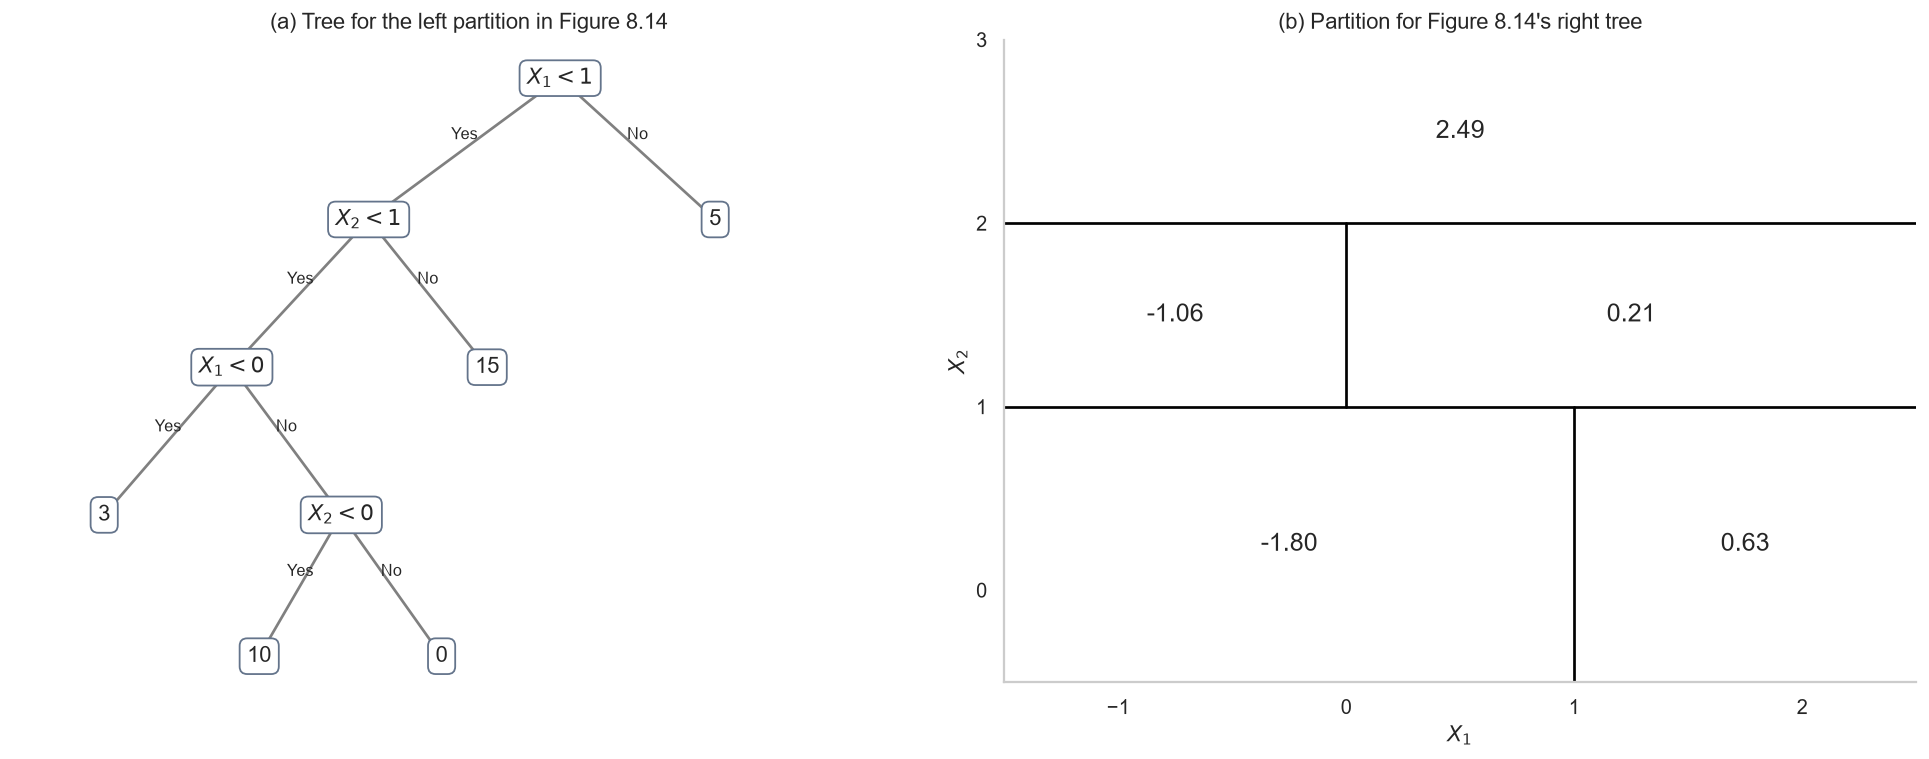

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
ax.set_axis_off()
positions = {'a': (.60, .94), 'b': (.39, .72), 'c': (.77, .72),
             'd': (.24, .49), 'e': (.52, .49), 'f': (.10, .26),
             'g': (.36, .26), 'h': (.27, .04), 'i': (.47, .04)}
labels = {'a': '$X_1 < 1$', 'b': '$X_2 < 1$', 'c': '5', 'd': '$X_1 < 0$',
          'e': '15', 'f': '3', 'g': '$X_2 < 0$', 'h': '10', 'i': '0'}
for parent, child, branch in [('a','b','Yes'),('a','c','No'),('b','d','Yes'),
                               ('b','e','No'),('d','f','Yes'),('d','g','No'),
                               ('g','h','Yes'),('g','i','No')]:
    p, q = positions[parent], positions[child]
    ax.plot([p[0],q[0]], [p[1],q[1]], color='gray', transform=ax.transAxes, zorder=1)
    ax.text((p[0]+q[0])/2, (p[1]+q[1])/2+.015, branch,
             transform=ax.transAxes, fontsize=9, ha='center')
for key, pos in positions.items():
    ax.text(*pos, labels[key], ha='center', va='center', transform=ax.transAxes,
             bbox={'boxstyle':'round,pad=.35', 'fc':'white', 'ec':'#64748b'}, zorder=2)
ax.set_title('(a) Tree for the left partition in Figure 8.14')
ax = axes[1]
ax.set(xlim=(-1.5, 2.5), ylim=(-.5, 3), xlabel='$X_1$', ylabel='$X_2$',
        title="(b) Partition for Figure 8.14's right tree")
ax.axhline(1, color='black')
ax.axhline(2, color='black')
ax.plot([1,1], [-.5,1], color='black')
ax.plot([0,0], [1,2], color='black')
for x,y,label in [(-.25,.25,'-1.80'),(1.75,.25,'0.63'),(-.75,1.5,'-1.06'),
                   (1.25,1.5,'0.21'),(.5,2.5,'2.49')]:
    ax.text(x,y,label,ha='center',va='center',fontsize=14)
ax.set_xticks([-1,0,1,2])
ax.set_yticks([0,1,2,3])
ax.grid(False)
plt.tight_layout()
plt.show()

## ISLR 9.7.2: nonlinear boundary

**(a)** $(1+X_1)^2+(2-X_2)^2=4$ is a circle centered at $(-1,2)$ with radius 2.

**(b)-(c)** The rule assigns Blue to the exterior ($>4$) and Red to the interior and boundary ($\le4$).

| Point | Squared distance from $(-1,2)$ | Class |
|---|---:|---|
| $(0,0)$ | 5 | Blue |
| $(-1,1)$ | 1 | Red |
| $(2,2)$ | 9 | Blue |
| $(3,8)$ | 52 | Blue |

**(d)** Expansion yields $X_1^2+X_2^2+2X_1-4X_2+1=0$, linear in augmented predictors $(X_1,X_1^2,X_2,X_2^2)$ with intercept 1 and coefficients $(2,1,-4,1)$, although nonlinear in $(X_1,X_2)$.

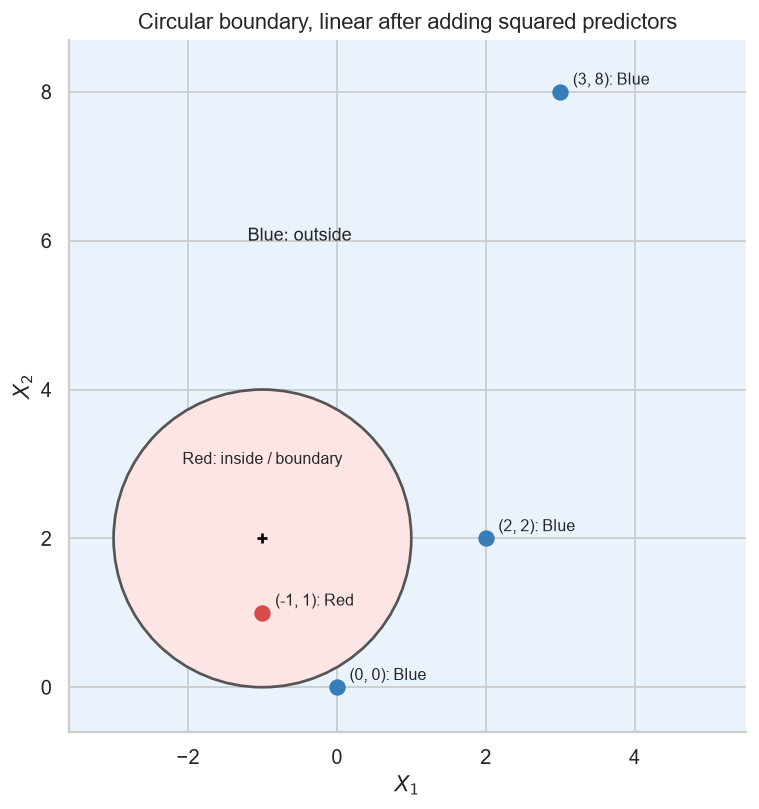

In [4]:
fig, ax = plt.subplots(figsize=(6, 7))
ax.set_facecolor('#eaf2fb')
circle = plt.Circle((-1,2), 2, facecolor='#fde5e5', edgecolor='#555555', linewidth=1.5)
ax.add_patch(circle)
query_points = np.array([[0,0],[-1,1],[2,2],[3,8]])
squared_distance = (query_points[:,0]+1)**2 + (query_points[:,1]-2)**2
for point, distance in zip(query_points, squared_distance):
    name, color = ('Blue','#377eb8') if distance > 4 else ('Red','#d64b4b')
    ax.scatter(*point, color=color, s=65, zorder=3)
    ax.annotate(f'{tuple(map(int, point))}: {name}', point, xytext=(7,4), textcoords='offset points', fontsize=9)
ax.scatter([-1],[2],marker='+',color='black')
ax.text(-1,3,'Red: inside / boundary',ha='center',fontsize=9)
ax.text(-.5,6,'Blue: outside',ha='center',fontsize=10)
ax.set(xlim=(-3.6,5.5),ylim=(-.6,8.7),xlabel='$X_1$',ylabel='$X_2$',
        title='Circular boundary, linear after adding squared predictors')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()